# 17  Introducción al Aprendizaje no Supervisado
Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from IPython.display import display

iris = load_iris(as_frame=True)
X_py = iris.data.copy()
especie_py = pd.Series(iris.target_names[iris.target], name="especie")
print("Dimensiones:", X_py.shape)

Dimensiones: (150, 4)


In [2]:
display(X_py.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
print(X_py.describe().round(2))

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.00               4.35   
75%                 6.40              3.30               5.10   
max                 7.90              4.40               6.90   

       petal width (cm)  
count            150.00  
mean               1.20  
std                0.76  
min                0.10  
25%                0.30  
50%                1.30  
75%                1.80  
max                2.50  


## 17.3.1 Calculamos distancias entre flores.

In [4]:
from scipy.spatial.distance import pdist, squareform

# Cinco primeras flores, solo las cuatro características numéricas
muestra_py = X_py.iloc[:5]
D_euclid_py = pd.DataFrame(squareform(pdist(muestra_py, metric="euclidean")))
D_manh_py = pd.DataFrame(squareform(pdist(muestra_py, metric="cityblock")))
print("Euclidiana:\n", D_euclid_py.round(3))

Euclidiana:
        0      1      2      3      4
0  0.000  0.539  0.510  0.648  0.141
1  0.539  0.000  0.300  0.332  0.608
2  0.510  0.300  0.000  0.245  0.510
3  0.648  0.332  0.245  0.000  0.648
4  0.141  0.608  0.510  0.648  0.000


In [5]:
print("Manhattan:\n", D_manh_py.round(3))

Manhattan:
      0    1    2    3    4
0  0.0  0.7  0.8  1.0  0.2
1  0.7  0.0  0.5  0.5  0.7
2  0.8  0.5  0.0  0.4  0.8
3  1.0  0.5  0.4  0.0  1.0
4  0.2  0.7  0.8  1.0  0.0


## 17.4 ¿Por qué importa la escala?

In [6]:
puntos_py = pd.DataFrame({"longitud_m": [1, 2, 4], "masa_g": [100, 110, 101]},
                          index=["A", "B", "C"])
print("Distancias con gramos:")

Distancias con gramos:


In [7]:
print(pd.DataFrame(squareform(pdist(puntos_py)), index=puntos_py.index,
                   columns=puntos_py.index).round(3))

        A      B      C
A   0.000  10.05  3.162
B  10.050   0.00  9.220
C   3.162   9.22  0.000


In [8]:
puntos_kg_py = puntos_py.copy()
puntos_kg_py["masa_g"] /= 1000
print("Distancias con kilogramos:")

Distancias con kilogramos:


In [9]:
print(pd.DataFrame(squareform(pdist(puntos_kg_py)), index=puntos_py.index,
                   columns=puntos_py.index).round(3))

     A    B    C
A  0.0  1.0  3.0
B  1.0  0.0  2.0
C  3.0  2.0  0.0


## 17.4.1 Centrado y estandarización.

In [10]:
from sklearn.preprocessing import StandardScaler

escalador_py = StandardScaler()
X_est_py = pd.DataFrame(escalador_py.fit_transform(X_py), columns=X_py.columns)
print("Medias estandarizadas:\n", X_est_py.mean().round(5))

Medias estandarizadas:
 sepal length (cm)   -0.0
sepal width (cm)    -0.0
petal length (cm)   -0.0
petal width (cm)    -0.0
dtype: float64


In [11]:
print("Desviaciones estándar poblacionales:\n", X_est_py.std(ddof=0).round(5))

Desviaciones estándar poblacionales:
 sepal length (cm)    1.0
sepal width (cm)     1.0
petal length (cm)    1.0
petal width (cm)     1.0
dtype: float64


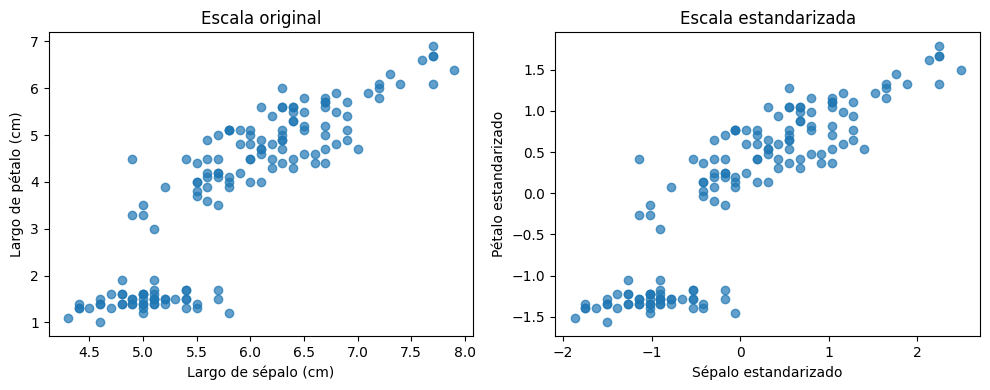

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(X_py.iloc[:, 0], X_py.iloc[:, 2], alpha=.7)
ax[0].set(xlabel="Largo de sépalo (cm)", ylabel="Largo de pétalo (cm)", title="Escala original")
ax[1].scatter(X_est_py.iloc[:, 0], X_est_py.iloc[:, 2], alpha=.7)
ax[1].set(xlabel="Sépalo estandarizado", ylabel="Pétalo estandarizado", title="Escala estandarizada")
plt.tight_layout()
plt.show()

## 17.5 Inspección antes de aplicar un algoritmo.

In [13]:
print("Faltantes por variable:\n", X_py.isna().sum())

Faltantes por variable:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [14]:
print("Filas duplicadas:", X_py.duplicated().sum())

Filas duplicadas: 1


In [15]:
print("Variables constantes:", X_py.columns[X_py.nunique() <= 1].tolist())

Variables constantes: []


In [16]:
print("Correlaciones:\n", X_py.corr().round(2))

Correlaciones:
                    sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)               1.00             -0.12               0.87   
sepal width (cm)               -0.12              1.00              -0.43   
petal length (cm)               0.87             -0.43               1.00   
petal width (cm)                0.82             -0.37               0.96   

                   petal width (cm)  
sepal length (cm)              0.82  
sepal width (cm)              -0.37  
petal length (cm)              0.96  
petal width (cm)               1.00  


## 17.6 Exploración visual: ¿hay grupos?

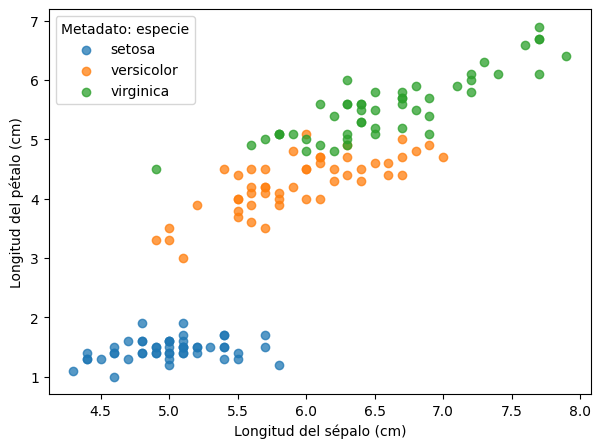

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre in iris.target_names:
    idx = especie_py == nombre
    ax.scatter(X_py.loc[idx, X_py.columns[0]], X_py.loc[idx, X_py.columns[2]],
               label=nombre, alpha=.75)
ax.set(xlabel="Longitud del sépalo (cm)", ylabel="Longitud del pétalo (cm)")
ax.legend(title="Metadato: especie")
plt.show()

## Ejercicio.

**17.7.1 Ejercicio 1: Supervisado o no supervisado.** Justifica si se trata de método supervisado o no supervisado y/o si es un problema de clasificación/regresión/agrupamiento, etc:

- predecir resistencia a un antibiótico a partir de genes;

    **R:** Supervisado y de clasificación porque tienes dos etiquetas: resistente o no.

- agrupar aislamientos por perfiles genéticos sin usar fenotipos;

    **R:** No supervisado y de agrupamiento porque no hay información de los fenotipos.

- representar muestras con dos coordenadas;

    **R:** No supervisado.

- predecir una concentración a partir de variables ambientales.

    **R:** Supervisado y regresión porque se estiman valores con datos conocidos.



**17.7.2 Ejercicio 2. Distancias a mano.** Dados 𝐴 =(1,1), 𝐵 =(4,5) y 𝐶 =(5,1), calcula 𝑑2⁡(𝐴,𝐵), 𝑑2⁡(𝐴,𝐶), 𝑑1⁡(𝐴,𝐵) y 𝑑1⁡(𝐴,𝐶).

¿Cuál es el vecino más cercano a 𝐴 con cada distancia?

**R:** Tanto con la distancia euclidiana y la distancia Manhattan el vecino más cercano es el C. 


In [18]:
datos = [[1,1], [4,5], [5,1]]

pd.DataFrame(squareform(pdist(datos, metric="euclidean")))

,0,1,2
0,0.0,5.000000,4.000000
1,5.0,0.000000,4.123106
2,4.0,4.123106,0.000000


In [19]:
pd.DataFrame(squareform(pdist(datos, metric="cityblock")))

,0,1,2
0,0.0,7.0,4.0
1,7.0,0.0,5.0
2,4.0,5.0,0.0


**17.7.3 Ejercicio 3. Unidades y estandarización.** Reproduce el ejemplo de longitud y masa.

- Identifica el vecino más próximo a A antes y después de convertir gramos a kilogramos.

In [20]:
puntos_py = pd.DataFrame({"longitud_m": [1, 2, 4], "masa_g": [100, 110, 101]},
                          index=["A", "B", "C"])
print("Distancias con gramos:")
print(pd.DataFrame(squareform(pdist(puntos_py)), index=puntos_py.index,
                   columns=puntos_py.index).round(3))

Distancias con gramos:
        A      B      C
A   0.000  10.05  3.162
B  10.050   0.00  9.220
C   3.162   9.22  0.000


In [21]:
puntos_kg_py = puntos_py.copy()
puntos_kg_py["masa_g"] /= 1000
print("Distancias con kilogramos:")
print(pd.DataFrame(squareform(pdist(puntos_kg_py)), index=puntos_py.index,
                   columns=puntos_py.index).round(3))

Distancias con kilogramos:
     A    B    C
A  0.0  1.0  3.0
B  1.0  0.0  2.0
C  3.0  2.0  0.0


Con la distancia en gramos, el vecino más cercano a A es C; mientras que con la distancia en kilogramos, es B.

- Estandariza las dos columnas y calcula las distancias.

In [22]:
escalador_py = StandardScaler()
puntos_est_py = pd.DataFrame(escalador_py.fit_transform(puntos_py), columns=puntos_py.columns)

In [23]:
print("Distancias con gramos:")
print(pd.DataFrame(squareform(pdist(puntos_est_py)), index=puntos_est_py.index,
                   columns=puntos_est_py.index).round(3))

Distancias con gramos:
       0      1      2
0  0.000  2.364  2.416
1  2.364  0.000  2.565
2  2.416  2.565  0.000


In [24]:
puntos_kg_est_py = puntos_est_py.copy()
puntos_kg_est_py["masa_g"] /= 1000
print("Distancias con kilogramos:")
print(pd.DataFrame(squareform(pdist(puntos_kg_est_py)), index=puntos_kg_est_py.index,
                   columns=puntos_kg_est_py.index).round(3))

Distancias con kilogramos:
       0      1      2
0  0.000  0.802  2.405
1  0.802  0.000  1.604
2  2.405  1.604  0.000


- Explica por qué centrar, por sí solo, no cambia la distancia euclidiana.

    **R:** Porque la distancia es invariante bajo traslación.

**17.7.4 Ejercicio 4. Explora Iris.** 

- Construye un gráfico usando las variables 2 y 4, sin colores por especie.

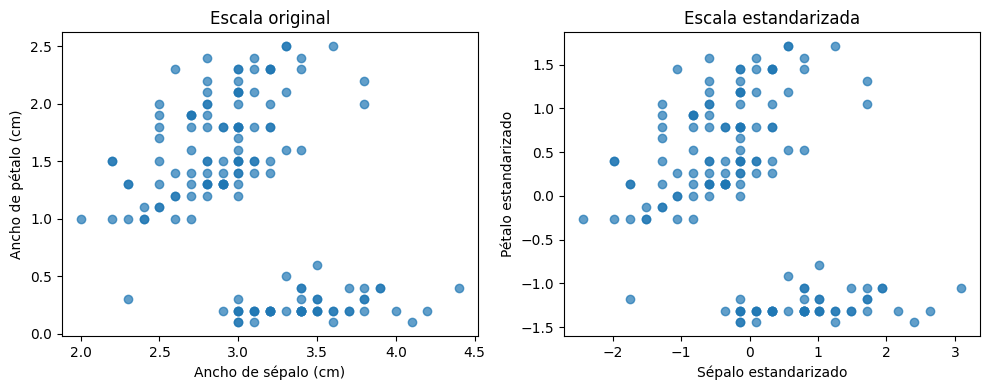

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(X_py.iloc[:, 1], X_py.iloc[:, 3], alpha=.7)
ax[0].set(xlabel="Ancho de sépalo (cm)", ylabel="Ancho de pétalo (cm)", title="Escala original")
ax[1].scatter(X_est_py.iloc[:, 1], X_est_py.iloc[:, 3], alpha=.7)
ax[1].set(xlabel="Sépalo estandarizado", ylabel="Pétalo estandarizado", title="Escala estandarizada")
plt.tight_layout()
plt.show()


- Repite con colores.

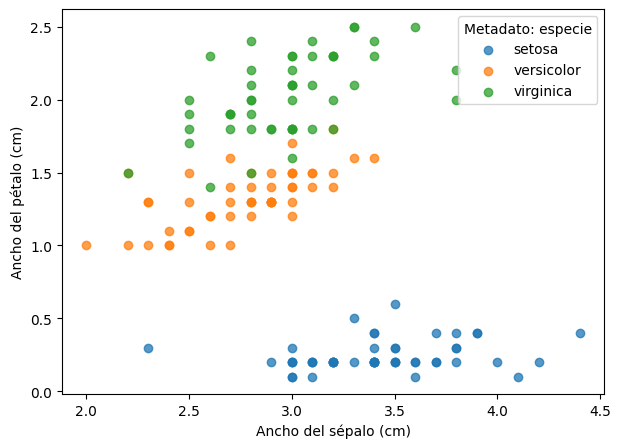

In [26]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre in iris.target_names:
    idx = especie_py == nombre
    ax.scatter(X_py.loc[idx, X_py.columns[1]], X_py.loc[idx, X_py.columns[3]],
               label=nombre, alpha=.75)
ax.set(xlabel="Ancho del sépalo (cm)", ylabel="Ancho del pétalo (cm)")
ax.legend(title="Metadato: especie")
plt.show()

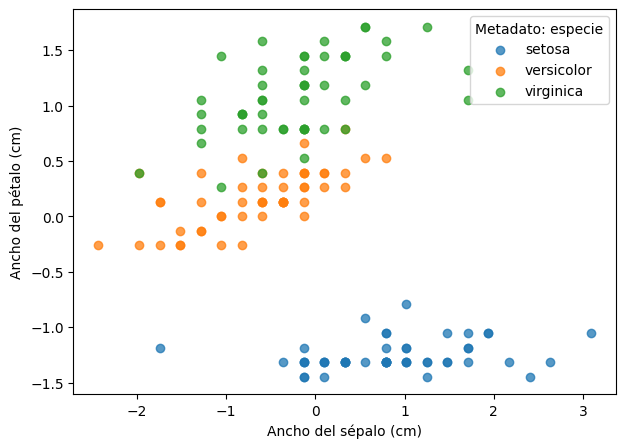

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))
for nombre in iris.target_names:
    idx = especie_py == nombre
    ax.scatter(X_est_py.loc[idx, X_py.columns[1]], X_est_py.loc[idx, X_py.columns[3]],
               label=nombre, alpha=.75)
ax.set(xlabel="Ancho del sépalo (cm)", ylabel="Ancho del pétalo (cm)")
ax.legend(title="Metadato: especie")
plt.show()

- Calcula las correlaciones y elige un par de variables fuertemente correlacionadas.

In [28]:
print("Correlaciones:\n", X_py.corr().round(2))

Correlaciones:
                    sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)               1.00             -0.12               0.87   
sepal width (cm)               -0.12              1.00              -0.43   
petal length (cm)               0.87             -0.43               1.00   
petal width (cm)                0.82             -0.37               0.96   

                   petal width (cm)  
sepal length (cm)              0.82  
sepal width (cm)              -0.37  
petal length (cm)              0.96  
petal width (cm)               1.00  


**R:** Entre las relaciones más fuertes están la de longitud del sépalo y la lóngitud del pétalo, y la longitud del pétalo y su ancho.

- Explica por qué las etiquetas de especie no deben incluirse como una quinta columna numérica para PCA o clustering no supervisado.

    Puede afectar los cálculos y haber fuga de datos.

**17.7.5 Reto adicional. ¿Es el mismo conjunto de datos?** Compara las distancias euclidianas entre las primeras cinco flores estandarizadas en R y Python. Explica por qué pueden diferir ligeramente y modifica uno de los procedimientos para que coincidan.

**R:** La manera de hacer sus cálculos son diferentes.

In [29]:
media_total = np.mean(X_py, axis=0)
desv_std_total = np.std(X_py, axis=0, ddof=1)
X_py_std = (X_py - media_total) / desv_std_total


muestra_py_std = X_py_std.iloc[:5]


D_mod = pd.DataFrame(squareform(pdist(muestra_py_std, metric="euclidean")))
print("Euclidiana:\n", D_mod.round(3))

Euclidiana:
        0      1      2      3      4
0  0.000  1.172  0.843  1.100  0.259
1  1.172  0.000  0.522  0.433  1.382
2  0.843  0.522  0.000  0.283  0.988
3  1.100  0.433  0.283  0.000  1.246
4  0.259  1.382  0.988  1.246  0.000
